# HW#9 – Part 1: Image Classification with Data Augmentation and Transfer Learning
**Course:** ECE-5831 &nbsp;|&nbsp; **Notebook:** `Module_9_1.ipynb`

## Goal
Classify **cat vs. dog** images when only a **very small training set** is available, and show how

1. **Data augmentation** (`DataAug`) artificially enlarges the training set,
2. a CNN trained **from scratch** on the limited data (`CatsDogsLimit`) behaves, and
3. a **pretrained network** (VGG16, ImageNet weights – `CatsDogsPre`) behaves on the *same* limited data.

## Requirements checklist
| Requirement | Where |
|---|---|
| `DataAug` – implement augmentation + display augmented images | Section 3 |
| `CatsDogsLimit` – train from scratch on limited data, show train/test results | Section 4 |
| `CatsDogsPre` – pretrained model, same limited data, show train/test results | Section 5 |
| Comparison: scratch vs. pretrained | Section 6 |

## 1. Imports and configuration

In [1]:
import os, random, shutil, zipfile, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = (150, 150)      # every image is resized to 150 x 150
BATCH    = 20
N_TRAIN, N_VAL, N_TEST = 150, 50, 100   # images PER CLASS  -> only 300 training images in total (limited!)
DATA_DIR = "limited_data"  # folder that will be created: train/ validation/ test/ -> cats/ dogs/

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.15.1
GPU devices: []


## 2. Build the *limited* dataset
The notebook builds a small, balanced dataset on disk:

| split | images per class | total |
|---|---|---|
| train (limited) | 150 | 300 |
| validation (used to monitor training) | 50 | 100 |
| test (never used for training/tuning) | 100 | 200 |

**Data sources (tried in this order):**
1. the official *cats_and_dogs_filtered* dataset (downloaded automatically by Keras), or
2. a backup copy `CAT1.zip` + `DOG1.zip` (real cat/dog photos): used from the notebook folder if present, otherwise downloaded automatically from GitHub. This kicks in if the official download is blocked (HTTP 403).

Both sources are shuffled with a fixed seed and split identically, so **both models see exactly the same images**.

In [2]:
OFFICIAL_URL = "https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip"
CLASSES = ["cats", "dogs"]
IMG_EXT = (".jpg", ".jpeg", ".png")

def _pool_from_official():
    zip_path = keras.utils.get_file("cats_and_dogs_filtered.zip", origin=OFFICIAL_URL, extract=True)
    root = os.path.join(os.path.dirname(zip_path), "cats_and_dogs_filtered")
    pool = {}
    for c in CLASSES:
        files = []
        for split in ("train", "validation"):
            files += sorted(glob.glob(os.path.join(root, split, c, "*")))
        pool[c] = [f for f in files if f.lower().endswith(IMG_EXT)]
    return pool, "official cats_and_dogs_filtered (downloaded)"

import urllib.request

def download(url, dest):
    """Download url -> dest (plain urllib with a browser-like header)."""
    print("Downloading", url)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r, open(dest, "wb") as f:
        shutil.copyfileobj(r, f)

GITHUB_ZIPS = "https://raw.githubusercontent.com/samialarabiyat/Cat-vs-Dog-Classification-with-Transfer-Learning/main/"

def _pool_from_local_zips():
    pool = {}
    for c, z in (("cats", "CAT1.zip"), ("dogs", "DOG1.zip")):
        if not os.path.exists(z):
            try:
                download(GITHUB_ZIPS + z, z)           # backup source on GitHub
            except Exception as e:
                raise FileNotFoundError(f"{z} not found next to the notebook and could not be downloaded ({e}). "
                                        "Put CAT1.zip and DOG1.zip in the same folder as this notebook.") from e
        out = f"_raw_{c}"
        if not os.path.isdir(out):
            with zipfile.ZipFile(z) as zf:
                zf.extractall(out)
        pool[c] = sorted(f for f in glob.glob(os.path.join(out, "**", "*"), recursive=True)
                         if f.lower().endswith(IMG_EXT))
    return pool, "backup copy CAT1.zip / DOG1.zip (cat/dog photos)"

def prepare_limited_dataset(base=DATA_DIR):
    """Create base/{train,validation,test}/{cats,dogs} with N_TRAIN / N_VAL / N_TEST images per class."""
    need = {"train": N_TRAIN, "validation": N_VAL, "test": N_TEST}
    if all(os.path.isdir(f"{base}/{s}/{c}") and len(os.listdir(f"{base}/{s}/{c}")) == n
           for s, n in need.items() for c in CLASSES):
        print("Limited dataset already prepared in:", base)
        return base
    try:
        pool, source = _pool_from_official()
    except Exception as e:
        print("Official download not available (", type(e).__name__, ") -> using backup copy (local zip files / GitHub)")
        pool, source = _pool_from_local_zips()
    print("Data source:", source)
    rng = random.Random(SEED)
    if os.path.isdir(base):
        shutil.rmtree(base)
    for c in CLASSES:
        files = list(pool[c]); rng.shuffle(files)
        assert len(files) >= sum(need.values()), f"not enough {c} images: {len(files)}"
        start = 0
        for split, n in need.items():
            dst = f"{base}/{split}/{c}"; os.makedirs(dst)
            for i, f in enumerate(files[start:start + n]):
                shutil.copy(f, os.path.join(dst, f"{c[:-1]}.{start + i}.jpg"))
            start += n
    return base

prepare_limited_dataset()
for s in ("train", "validation", "test"):
    print(f"{s:>10}:", {c: len(os.listdir(f'{DATA_DIR}/{s}/{c}')) for c in CLASSES})

Official download not available ( Exception ) -> using backup copy (local zip files / GitHub)
Data source: backup copy CAT1.zip / DOG1.zip (cat/dog photos)
     train: {'cats': 150, 'dogs': 150}
validation: {'cats': 50, 'dogs': 50}
      test: {'cats': 100, 'dogs': 100}


## 3. `DataAug` – data augmentation
With only 300 training images a CNN quickly **memorises** them (over-fitting). Data augmentation produces many *new, slightly different* versions of each training image through random transformations:

* random horizontal flip
* random rotation (±~15°)
* random zoom (±20 %)
* random translation (±10 %)
* random contrast

The `DataAug` class wraps these Keras preprocessing layers in one `Sequential` block. The same block is later placed **inside** the scratch model (it is only active while training, never at test time).

Found 300 files belonging to 2 classes.
Class names: ['cats', 'dogs']


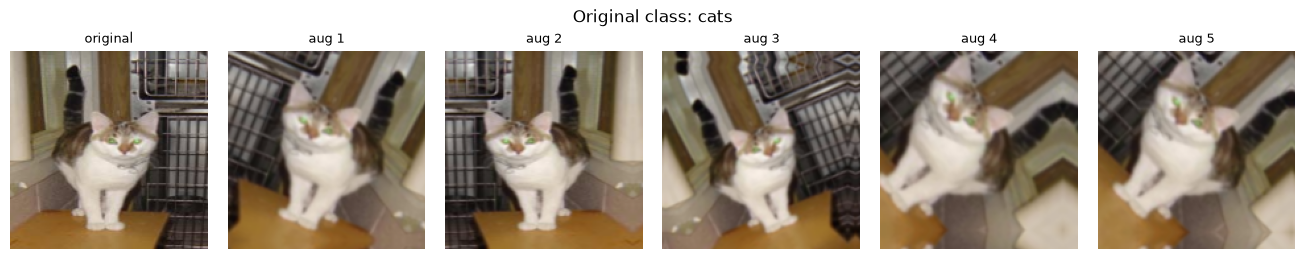

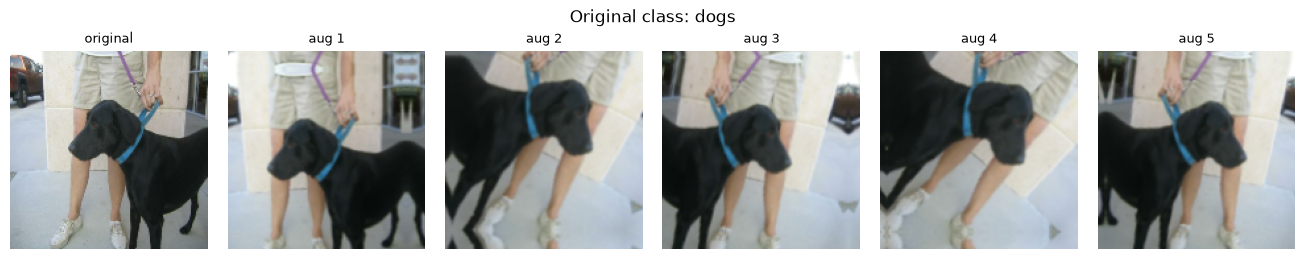

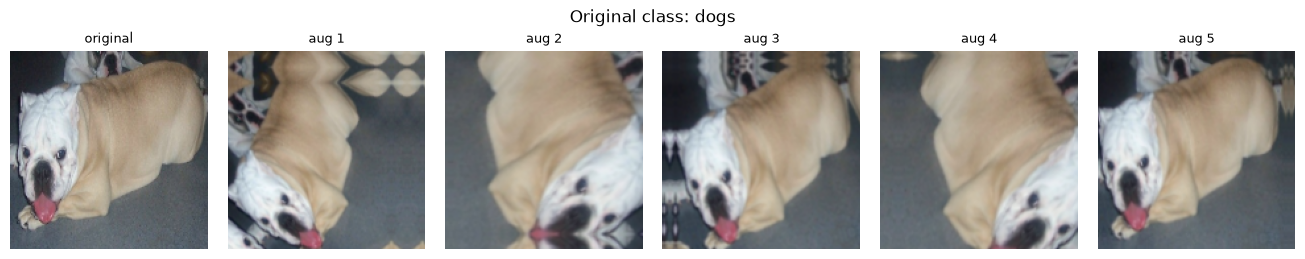

In [3]:
class DataAug:
    """Data augmentation helper (flip, rotation, zoom, translation, contrast)."""

    def __init__(self, seed=SEED):
        self.seed = seed
        self.augmentation = keras.Sequential([
            layers.RandomFlip("horizontal", seed=seed),
            layers.RandomRotation(0.15, seed=seed),
            layers.RandomZoom(0.2, seed=seed),
            layers.RandomTranslation(0.1, 0.1, seed=seed),
            layers.RandomContrast(0.1, seed=seed),
        ], name="data_augmentation")

    def get_layer(self):
        """Return the augmentation block so it can be used inside a model."""
        return self.augmentation

    def augment(self, images):
        """Augment a batch of images (training=True forces the random transforms on)."""
        return self.augmentation(images, training=True)

    def show_augmented(self, image, n=8, title="Augmented versions of one image"):
        """Show the original image followed by n augmented versions of it."""
        image = tf.cast(image, tf.float32)
        batch = tf.repeat(tf.expand_dims(image, 0), n, axis=0)
        aug = self.augment(batch).numpy()
        cols = n + 1
        fig, axes = plt.subplots(1, cols, figsize=(2.2 * cols, 2.6))
        axes[0].imshow(image.numpy().astype("uint8")); axes[0].set_title("original", fontsize=9)
        for i in range(n):
            axes[i + 1].imshow(np.clip(aug[i], 0, 255).astype("uint8"))
            axes[i + 1].set_title(f"aug {i + 1}", fontsize=9)
        for ax in axes: ax.axis("off")
        fig.suptitle(title); plt.tight_layout(); plt.show()

    def show_dataset_samples(self, dataset, n_images=3, n_aug=5):
        """Take n_images originals from a tf.data dataset and show n_aug augmentations of each."""
        images, labels = next(iter(dataset.unbatch().batch(n_images)))
        names = dataset.class_names
        for img, lab in zip(images, labels):
            self.show_augmented(img, n=n_aug,
                                title=f"Original class: {names[int(lab.numpy().ravel()[0])]}")

# --- demonstration on the limited TRAIN set -------------------------------------------------
raw_train = keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/train", image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="binary", shuffle=True, seed=SEED)
print("Class names:", raw_train.class_names)

aug = DataAug()
aug.show_dataset_samples(raw_train, n_images=3, n_aug=5)

**Observation.** Each row shows one original training photo followed by five different augmented variants – the animal is flipped, rotated, zoomed or shifted, but is still clearly a cat or a dog. Every epoch the network therefore sees *different* variants of the same 300 photos, which acts as a regulariser against over-fitting.

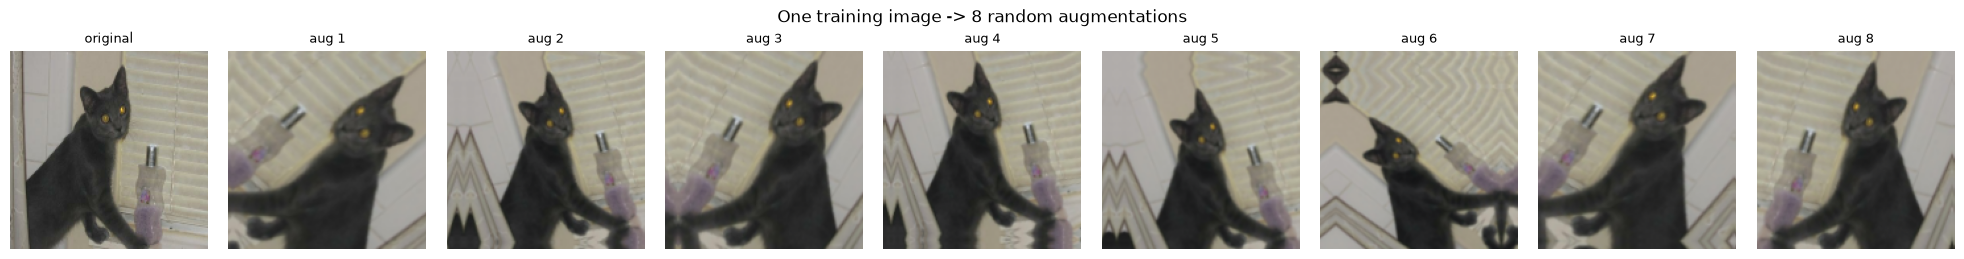

In [4]:
# A second view: a 3x3 grid of augmentations of the same single image
img0, _ = next(iter(raw_train.unbatch().take(1)))
aug.show_augmented(img0, n=8, title="One training image -> 8 random augmentations")

## 4. `CatsDogsLimit` – CNN trained **from scratch** on the limited data
Architecture (small VGG-style CNN):

`Rescaling(1/255) → DataAug → [Conv(32)-MaxPool] → [Conv(64)-MaxPool] → [Conv(128)-MaxPool] → [Conv(128)-MaxPool] → Flatten → Dropout(0.5) → Dense(256) → Dense(1, sigmoid)`

* loss: binary cross-entropy, optimizer: RMSprop (lr = 1e-3), metric: accuracy
* `EarlyStopping` on validation loss (restores the best weights)

In [5]:
def load_split(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        f"{DATA_DIR}/{split}", image_size=IMG_SIZE, batch_size=BATCH,
        label_mode="binary", shuffle=shuffle, seed=SEED)

def plot_history(history, title):
    h = history.history
    ep = range(1, len(h["accuracy"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(ep, h["accuracy"], "o-", label="training"); ax[0].plot(ep, h["val_accuracy"], "s-", label="validation")
    ax[0].set_title(f"{title} – accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, h["loss"], "o-", label="training"); ax[1].plot(ep, h["val_loss"], "s-", label="validation")
    ax[1].set_title(f"{title} – loss"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()


class CatsDogsLimit:
    """Cat/dog classifier trained from scratch on the limited dataset (with data augmentation)."""

    def __init__(self, epochs=40, augment=True):
        self.epochs, self.augment = epochs, augment
        self.model, self.history = None, None
        self.train_ds = self.val_ds = self.test_ds = None

    def load_data(self):
        self.train_ds = load_split("train", True)
        self.val_ds   = load_split("validation", False)
        self.test_ds  = load_split("test", False)
        return self

    def build_model(self):
        keras.utils.set_random_seed(SEED)
        inputs = keras.Input(shape=IMG_SIZE + (3,))
        x = layers.Rescaling(1. / 255)(inputs)
        if self.augment:
            x = DataAug().get_layer()(x)           # only active during training
        for f in (32, 64, 128, 128):
            x = layers.Conv2D(f, 3, activation="relu")(x)
            x = layers.MaxPooling2D(2)(x)
        x = layers.Flatten()(x)
        x = layers.Dropout(0.5)(x)
        x = layers.Dense(256, activation="relu")(x)
        outputs = layers.Dense(1, activation="sigmoid")(x)
        self.model = keras.Model(inputs, outputs, name="cats_dogs_scratch")
        self.model.compile(loss="binary_crossentropy",
                           optimizer=keras.optimizers.RMSprop(1e-3), metrics=["accuracy"])
        return self.model

    def train(self):
        cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
        self.history = self.model.fit(self.train_ds, validation_data=self.val_ds,
                                      epochs=self.epochs, callbacks=cb, verbose=2)
        return self.history

    def evaluate(self):
        res = {}
        for name, ds in (("train", self.train_ds), ("validation", self.val_ds), ("test", self.test_ds)):
            loss, acc = self.model.evaluate(ds, verbose=0)
            res[name] = {"loss": loss, "accuracy": acc}
        return res

    def plot_history(self):
        plot_history(self.history, "Scratch CNN (limited data)")

    def run(self):
        self.load_data(); self.build_model(); self.model.summary(); self.train(); return self.evaluate()

In [6]:
scratch = CatsDogsLimit(epochs=40, augment=True)
scratch.load_data()
scratch.build_model()
scratch.model.summary()

Found 300 files belonging to 2 classes.
Found 100 files belonging to 2 classes.
Found 200 files belonging to 2 classes.


Model: "cats_dogs_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,846,977 (7.05 MB)

 Trainable params: 1,846,977 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history_scratch = scratch.train()

Epoch 1/40


c:\Users\manid\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


15/15 - 14s - 921ms/step - accuracy: 0.4833 - loss: 0.7101 - val_accuracy: 0.5000 - val_loss: 0.6930
Epoch 2/40
15/15 - 8s - 549ms/step - accuracy: 0.5000 - loss: 0.6950 - val_accuracy: 0.5100 - val_loss: 0.6924
Epoch 3/40
15/15 - 10s - 681ms/step - accuracy: 0.5000 - loss: 0.6940 - val_accuracy: 0.5300 - val_loss: 0.6921
Epoch 4/40
15/15 - 8s - 535ms/step - accuracy: 0.4700 - loss: 0.6947 - val_accuracy: 0.6400 - val_loss: 0.6924
Epoch 5/40
15/15 - 6s - 407ms/step - accuracy: 0.5100 - loss: 0.6925 - val_accuracy: 0.5000 - val_loss: 0.6941
Epoch 6/40
15/15 - 8s - 506ms/step - accuracy: 0.4867 - loss: 0.7321 - val_accuracy: 0.5000 - val_loss: 0.6918
Epoch 7/40
15/15 - 8s - 525ms/step - accuracy: 0.4967 - loss: 0.6929 - val_accuracy: 0.5300 - val_loss: 0.6896
Epoch 8/40
15/15 - 8s - 504ms/step - accuracy: 0.5400 - loss: 0.6952 - val_accuracy: 0.5400 - val_loss: 0.6901
Epoch 9/40
15/15 - 5s - 346ms/step - accuracy: 0.5367 - loss: 0.6922 - val_accuracy: 0.6500 - val_loss: 0.6906
Epoch 10/4

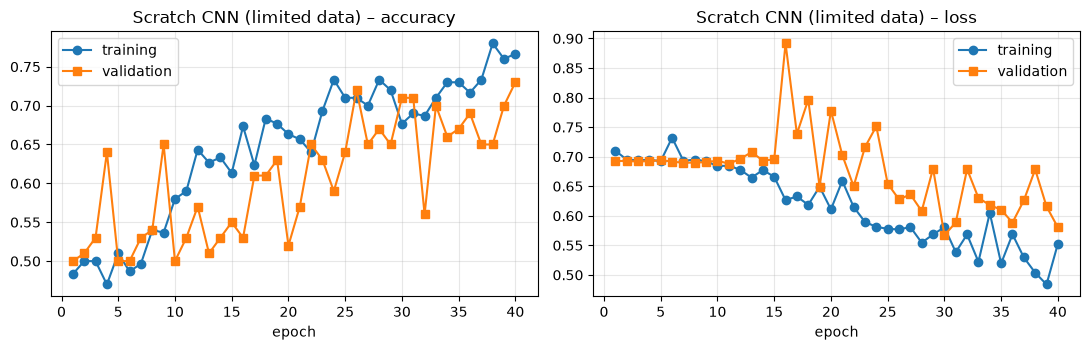

Scratch model on limited data (300 training images)
              loss  accuracy
train       0.4825    0.7667
validation  0.5672    0.7100
test        0.5578    0.7050


In [8]:
scratch.plot_history()
res_scratch = scratch.evaluate()
print("Scratch model on limited data (300 training images)")
print(pd.DataFrame(res_scratch).T.round(4))

## 5. `CatsDogsPre` – **pretrained** network on the *same* limited data
Here we reuse **VGG16 trained on ImageNet** (1.4 M images, 1000 classes) as a frozen *feature extractor* (the convolutional base, `include_top=False`). Only a small new classifier head (`Flatten → Dense(256) → Dropout → Dense(1)`) is trained on our 300 images.

For speed, the training/validation/test images are passed through the frozen base **once** and the resulting feature maps (4×4×512) are cached – this is mathematically the same as running a frozen base in every epoch (no augmentation is used here).

The pretrained weights are loaded with `weights="imagenet"`; if that download is blocked, the same weights are downloaded once from GitHub and saved as `vgg16_notop.h5` next to the notebook.

In [9]:
class CatsDogsPre:
    """Cat/dog classifier using a pretrained VGG16 base (feature extraction) on the same limited data."""

    LOCAL_WEIGHTS = "vgg16_notop.h5"
    GITHUB_WEIGHTS = "https://github.com/fchollet/deep-learning-models/releases/download/v0.1/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"

    def __init__(self, epochs=30):
        self.epochs = epochs
        self.base, self.model, self.history = None, None, None
        self.feats, self.labels = {}, {}

    def load_pretrained_base(self):
        shape = IMG_SIZE + (3,)
        try:
            self.base = keras.applications.VGG16(weights="imagenet", include_top=False, input_shape=shape)
            print("Loaded VGG16 ImageNet weights (download).")
        except Exception as e:
            if not os.path.exists(self.LOCAL_WEIGHTS):
                try:
                    download(self.GITHUB_WEIGHTS, self.LOCAL_WEIGHTS)      # ~58 MB, one time
                except Exception as e2:
                    raise RuntimeError("Could not get the ImageNet weights. Download vgg16_notop.h5 manually "
                                       "and put it next to this notebook.") from e2
            self.base = keras.applications.VGG16(weights=self.LOCAL_WEIGHTS, include_top=False, input_shape=shape)
            print("Keras download unavailable -> loaded VGG16 ImageNet weights from", self.LOCAL_WEIGHTS)
        self.base.trainable = False          # freeze the convolutional base
        return self.base

    def extract_features(self):
        for split in ("train", "validation", "test"):
            ds = load_split(split, shuffle=False)        # fixed order -> labels stay aligned
            fs, ls = [], []
            for x, y in ds:
                fs.append(self.base.predict(keras.applications.vgg16.preprocess_input(x.numpy()), verbose=0))
                ls.append(y.numpy().ravel())
            self.feats[split], self.labels[split] = np.concatenate(fs), np.concatenate(ls)
            print(f"{split:>10}: features {self.feats[split].shape}, labels {self.labels[split].shape}")

    def build_model(self):
        keras.utils.set_random_seed(SEED)
        inputs = keras.Input(shape=self.feats["train"].shape[1:])
        x = layers.Flatten()(inputs)
        x = layers.Dense(256, activation="relu")(x)
        x = layers.Dropout(0.5)(x)
        outputs = layers.Dense(1, activation="sigmoid")(x)
        self.model = keras.Model(inputs, outputs, name="cats_dogs_pretrained_head")
        self.model.compile(loss="binary_crossentropy",
                           optimizer=keras.optimizers.RMSprop(2e-5), metrics=["accuracy"])
        return self.model

    def train(self):
        cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
        self.history = self.model.fit(self.feats["train"], self.labels["train"],
                                      validation_data=(self.feats["validation"], self.labels["validation"]),
                                      epochs=self.epochs, batch_size=BATCH, callbacks=cb, verbose=2)
        return self.history

    def evaluate(self):
        res = {}
        for split in ("train", "validation", "test"):
            loss, acc = self.model.evaluate(self.feats[split], self.labels[split], verbose=0)
            res[split] = {"loss": loss, "accuracy": acc}
        return res

    def plot_history(self):
        plot_history(self.history, "Pretrained VGG16 + new head (limited data)")

    def build_full_model(self):
        """Assemble base + trained head into one end-to-end model that accepts raw images."""
        inputs = keras.Input(shape=IMG_SIZE + (3,))
        x = keras.applications.vgg16.preprocess_input(inputs)
        return keras.Model(inputs, self.model(self.base(x)), name="cats_dogs_pretrained_full")

In [10]:
pre = CatsDogsPre(epochs=30)
pre.load_pretrained_base()
print("Frozen VGG16 base: trainable =", pre.base.trainable, "| parameters =", f"{pre.base.count_params():,}")
pre.extract_features()
pre.build_model()
pre.model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Loaded VGG16 ImageNet weights (download).
Frozen VGG16 base: trainable = False | parameters = 14,714,688
Found 300 files belonging to 2 classes.
     train: features (300, 4, 4, 512), labels (300,)
Found 100 files belonging to 2 classes.
validation: features (100, 4, 4, 512), labels (100,)
Found 200 files belonging to 2 classes.
      test: features (200, 4, 4, 512), labels (200,)


Model: "cats_dogs_pretrained_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,097,665 (8.00 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history_pre = pre.train()

Epoch 1/30
15/15 - 2s - 156ms/step - accuracy: 0.5933 - loss: 8.6988 - val_accuracy: 0.6900 - val_loss: 3.3890
Epoch 2/30
15/15 - 1s - 65ms/step - accuracy: 0.7467 - loss: 3.6007 - val_accuracy: 0.7800 - val_loss: 2.1501
Epoch 3/30
15/15 - 1s - 58ms/step - accuracy: 0.8067 - loss: 2.8767 - val_accuracy: 0.8300 - val_loss: 1.6722
Epoch 4/30
15/15 - 1s - 61ms/step - accuracy: 0.8600 - loss: 2.3149 - val_accuracy: 0.8500 - val_loss: 1.4629
Epoch 5/30
15/15 - 1s - 47ms/step - accuracy: 0.8367 - loss: 2.0343 - val_accuracy: 0.8600 - val_loss: 1.2954
Epoch 6/30
15/15 - 1s - 39ms/step - accuracy: 0.8833 - loss: 1.3043 - val_accuracy: 0.8700 - val_loss: 1.2211
Epoch 7/30
15/15 - 1s - 41ms/step - accuracy: 0.9167 - loss: 1.1206 - val_accuracy: 0.8900 - val_loss: 0.9979
Epoch 8/30
15/15 - 1s - 59ms/step - accuracy: 0.9400 - loss: 0.7123 - val_accuracy: 0.9100 - val_loss: 0.8648
Epoch 9/30
15/15 - 1s - 44ms/step - accuracy: 0.9467 - loss: 0.4761 - val_accuracy: 0.9100 - val_loss: 0.8028
Epoch 10/

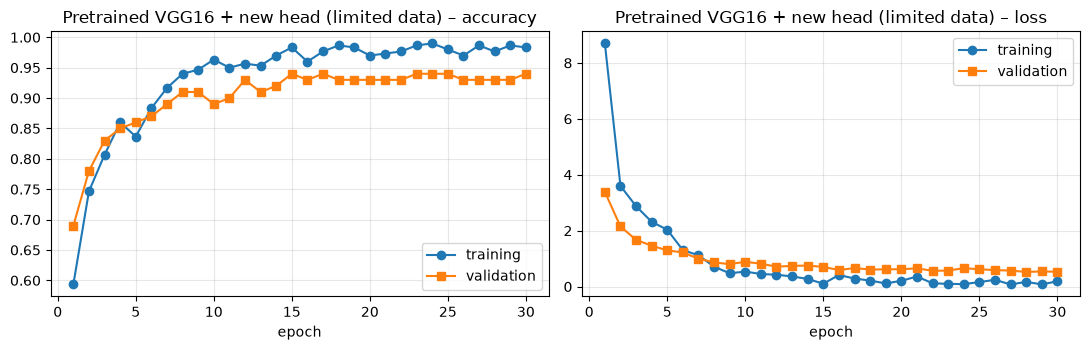

Pretrained VGG16 on the same limited data (300 training images)
              loss  accuracy
train       0.0000      1.00
validation  0.5250      0.93
test        0.6628      0.96


In [12]:
pre.plot_history()
res_pre = pre.evaluate()
print("Pretrained VGG16 on the same limited data (300 training images)")
print(pd.DataFrame(res_pre).T.round(4))

In [13]:
# Sanity check: the assembled end-to-end model gives the same test accuracy on raw images
full = pre.build_full_model()
full.compile(loss="binary_crossentropy", metrics=["accuracy"])
print("End-to-end pretrained model, test accuracy:", round(full.evaluate(load_split("test", False), verbose=0)[1], 4))

Found 200 files belonging to 2 classes.
End-to-end pretrained model, test accuracy: 0.96


## 6. Comparison: scratch model vs. pretrained model (same limited dataset)

In [14]:
rows = []
for name, res in (("From scratch (CNN + augmentation)", res_scratch), ("Pretrained VGG16 (frozen base + head)", res_pre)):
    rows.append({"Model": name,
                 "Train acc": res["train"]["accuracy"], "Val acc": res["validation"]["accuracy"],
                 "Test acc": res["test"]["accuracy"],
                 "Train loss": res["train"]["loss"], "Test loss": res["test"]["loss"],
                 "Train-Test gap": res["train"]["accuracy"] - res["test"]["accuracy"]})
comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison

,Train acc,Val acc,Test acc,Train loss,Test loss,Train-Test gap
Model,,,,,,
From scratch (CNN + augmentation),0.7667,0.71,0.705,0.4825,0.5578,0.0617
Pretrained VGG16 (frozen base + head),1.0000,0.93,0.960,0.0000,0.6628,0.0400


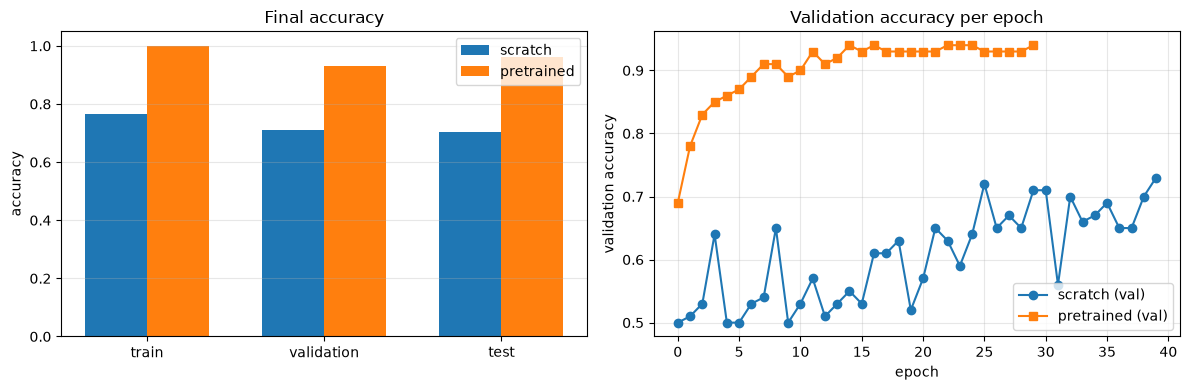

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# (a) final accuracies
x = np.arange(3); w = 0.35
ax[0].bar(x - w/2, [res_scratch[s]["accuracy"] for s in ("train", "validation", "test")], w, label="scratch")
ax[0].bar(x + w/2, [res_pre[s]["accuracy"]     for s in ("train", "validation", "test")], w, label="pretrained")
ax[0].set_xticks(x); ax[0].set_xticklabels(["train", "validation", "test"]); ax[0].set_ylim(0, 1.05)
ax[0].set_ylabel("accuracy"); ax[0].set_title("Final accuracy"); ax[0].legend(); ax[0].grid(axis="y", alpha=.3)

# (b) validation accuracy during training
ax[1].plot(history_scratch.history["val_accuracy"], "o-", label="scratch (val)")
ax[1].plot(history_pre.history["val_accuracy"], "s-", label="pretrained (val)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy"); ax[1].set_title("Validation accuracy per epoch")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [16]:
s_test, p_test = res_scratch["test"]["accuracy"], res_pre["test"]["accuracy"]
better = "pretrained" if p_test > s_test else "scratch"
print(f"Test accuracy  scratch    : {s_test:.2%}")
print(f"Test accuracy  pretrained : {p_test:.2%}")
print(f"-> The {better} model is better by {abs(p_test - s_test) * 100:.1f} percentage points on the held-out test set.")

Test accuracy  scratch    : 70.50%
Test accuracy  pretrained : 96.00%
-> The pretrained model is better by 25.5 percentage points on the held-out test set.


### Discussion
* **From scratch.** The network has to learn *everything* – edges, textures, shapes and the cat/dog concept – from just 300 images. Even with data augmentation and dropout, there is too little data, so accuracy on unseen images stays well below what the pretrained model reaches, and validation accuracy is noisy from epoch to epoch.
* **Pretrained (VGG16).** The convolutional base already knows general visual features from ImageNet (which even contains many cat and dog breeds). We only train a tiny classifier on top, so it converges in a few epochs and generalises far better to unseen images from the same 300 training images.
* **Train–test gap.** The pretrained model reaches very high training accuracy and also a high test accuracy, while the scratch model is limited on both; the table above shows the numbers.
* **Take-away.** When the labelled dataset is small, **transfer learning is the most effective tool**, and **data augmentation** is the cheap way to squeeze more out of a model that must be trained from scratch. The two can be combined (augmentation + fine-tuning the top VGG block) for further gains.

*Note: the exact numbers can vary slightly between runs/machines (random initialisation, library versions); with the fixed seeds used here they are reproducible on the same setup.*